In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

In [2]:
class_tab = pd.read_csv('Unifxed_class_tab.csv')

class_tab = class_tab.set_index('Sample') 

In [3]:
class_tab.shape

(279, 2999)

In [4]:
data_target = class_tab.loc[:,'Species']
                            
data_predictors = class_tab.iloc[:,:2998]

In [5]:
data_predictors.head()

,PKNH_01_v2 53971,PKNH_01_v2 55790,PKNH_01_v2 62289,PKNH_01_v2 65382,PKNH_01_v2 67815,PKNH_01_v2 69666,PKNH_01_v2 80532,PKNH_01_v2 80595,PKNH_01_v2 85363,PKNH_01_v2 86333,...,PKNH_14_v2 3162158,PKNH_14_v2 3180755,PKNH_14_v2 3181251,PKNH_14_v2 3181434,PKNH_14_v2 3182733,PKNH_14_v2 3197259,PKNH_API_v2 17538,PKNH_API_v2 24749,PKNH_MIT_v2 2640,PKNH_MIT_v2 3785
Sample,,,,,,,,,,,,,,,,,,,,,
SAMEA104419839,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
SAMEA104419840,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
SAMEA104419841,1.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0
SAMEA104419842,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
SAMEA104419843,1.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0


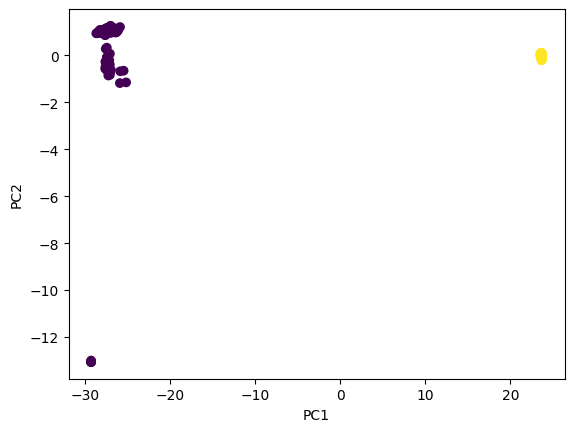

In [6]:
from sklearn.decomposition import PCA

pca = PCA(n_components = 10)
X_pca = pca.fit_transform(data_predictors)

plt.scatter(X_pca[:, 0], X_pca[:, 1], c=pd.factorize(data_target)[0])
plt.xlabel('PC1')
plt.ylabel('PC2')
plt.show()

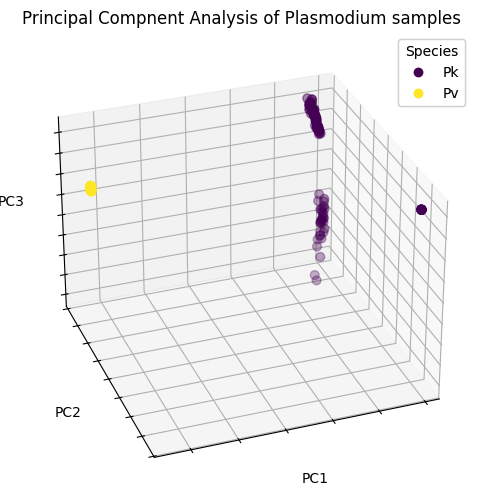

In [9]:
target_codes, target_labels = pd.factorize(data_target)

fig = plt.figure(1, figsize=(8, 6))
ax = fig.add_subplot(111, projection="3d", elev=-150, azim=110)

scatter = ax.scatter(
    X_pca[:, 0],
    X_pca [:, 1],
    X_pca [:, 2],
    c=target_codes,
    s=40,
)

ax.set(
    title="Principal Compnent Analysis of Plasmodium samples",
    xlabel="PC1",
    ylabel="PC2",
    zlabel="PC3",
)
ax.xaxis.set_ticklabels([])
ax.yaxis.set_ticklabels([])
ax.zaxis.set_ticklabels([])

legend1 = ax.legend(
    scatter.legend_elements()[0],
    target_labels.tolist(),
    loc="upper right",
    title="Species",
)
ax.add_artist(legend1)

plt.savefig('Species_PCA.png')

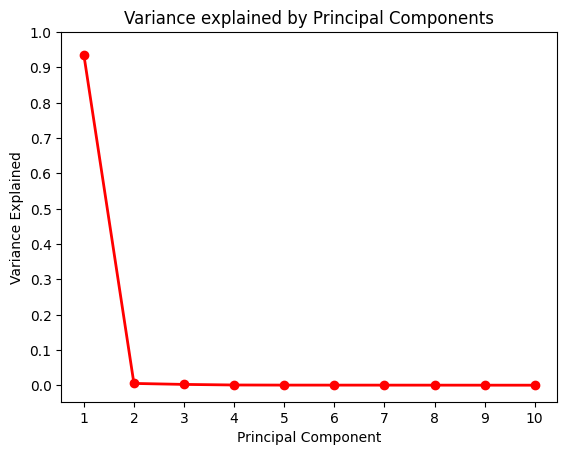

In [18]:
PC_values = np.arange(pca.n_components_) + 1
plt.plot(PC_values, pca.explained_variance_ratio_, 'o-', linewidth=2, color='red')
plt.xticks(range(1,11))
plt.yticks([0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1])
plt.title('Variance explained by Principal Components')
plt.xlabel('Principal Component')
plt.ylabel('Variance Explained')
plt.savefig('Species_Scree.png')

In [34]:
loadings = pd.DataFrame(pca.components_[0], columns=['PC1'], index=data_predictors.columns)

loadings = loadings["PC1"].abs().sort_values(ascending=False)

loadings = pd.DataFrame(loadings)

In [36]:
loadings.to_csv('PCA_top_loadings.csv')